----

# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


## Plan de solución

Escribe aquí tu plan de solución para el Paso 1. Descripción de los datos.
El proposito es simple: 
1. importar las librerias de pandas, numpy y matplotlib
2. leer los archivos .csv a partir de read.csv()
3. llamar los métodos .info(), .head() y .shape para determinar situaciones de interés para el análisis posterior. En caso de encontrar algo por mejorar desde la lectura del archivo, es un método que se mejora de manera cíclica.

In [94]:
# importar librerías
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

In [95]:
# leer conjuntos de datos en los DataFrames
df_orders = pd.read_csv('/datasets/instacart_orders.csv', sep = ';')
df_products = pd.read_csv('/datasets/products.csv', sep = ';')
df_ordprod = pd.read_csv('/datasets/order_products.csv', sep = ';')
df_aisles = pd.read_csv('/datasets/aisles.csv', sep = ';')
df_departments = pd.read_csv('/datasets/departments.csv', sep = ';')

In [96]:
# mostrar información del DataFrame
print(df_orders.info())
print()
print(df_orders.head())
print()
print(df_orders.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB
None

   order_id  user_id  order_number  order_dow  order_hour_of_day  \
0   1515936   183418            11          6                 13   
1   1690866   163593             5          5                 12   
2   1454967    39980             4          5                 19   
3   1768857    82516            56          0                 20   
4   3007858   196724             2          4                

In [97]:
# mostrar información del DataFrame
print(df_products.info())
print()
print(df_products.head())
print()
print(df_products.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB
None

   product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt       104   
2           3               Robust Golden Unsweetened Oolong Tea        94   
3           4  Smart Ones Classic Favorites Mini Rigatoni Wit...        38   
4           5                          Green Chile Anytime Sauce         5   

   department_id  
0             19  
1             13  
2              7  
3              1  
4             

In [98]:
# mostrar información del DataFrame
print(df_ordprod.info())
print()
print(df_ordprod.head())
print()
print(df_ordprod.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
None

   order_id  product_id  add_to_cart_order  reordered
0   2141543       11440               17.0          0
1    567889        1560                1.0          1
2   2261212       26683                1.0          1
3    491251        8670               35.0          1
4   2571142        1940                5.0          1

(4545007, 4)


In [99]:
# mostrar información del DataFrame
print(df_aisles.info())
print()
print(df_aisles.head())
print()
print(df_aisles.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB
None

   aisle_id                       aisle
0         1       prepared soups salads
1         2           specialty cheeses
2         3         energy granola bars
3         4               instant foods
4         5  marinades meat preparation

(134, 2)


In [100]:
# mostrar información del DataFrame
print(df_departments.info())
print()
print(df_departments.head())
print()
print(df_departments.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 464.0+ bytes
None

   department_id department
0              1     frozen
1              2      other
2              3     bakery
3              4    produce
4              5    alcohol

(21, 2)


## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 1. Descripción de los datos.
1. El Dataframe de orders tiene 478967 entradas en 6 columnas, donde solamente una columna, la de los días transcurridos desde el último pedido, tiene menor valores que la base original. La razón para ello puede ser que sea solamente el primer pedido realizado, pero se debe indagar mas al respecto.
2. El DataFrame de products tiene 49694 entradas en 4 columnas, la columna de nombre del producto tiene valores no especificados que se deben limpiar antes del análisis, además los nombres todos inician con mayúsculas, situación que también debe preprocesarse antes del análisis.
3. Este DataFrame es el más extenso, tiene 4545007 entradas, con los valores en 4 columnas y aparentemente sin datos por preprocesar.
4. Es un DataFrame pequeño de 134 entradas y 2 columnas sin datos faltantes
5. Es el DataFrame mas pequeño de todos con 21 entradas y dos columnas

finalmente, los DataFrames ya se encuentran estructurados adecuadamente. Se encuentran valores estratégicos ausentes y en el siguiente paso se analizarán con detenimiento.

# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

## Plan de solución

Escribe aquí tu plan para el Paso 2. Preprocesamiento de los datos.
Se debe hacer una limpieza de datos que incluye:
1. Dejar todos los nombres de productos en minúsculas.
2. Revisar presencia de duplicados y hacer el tratamiento correspondiente.
3. Revisar presencia de datos ausentes y analizar el tratamiendo respectivo.
4. Organizar que los datos queden de la mejor forma para ser tratados.

## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [101]:
# Revisa si hay pedidos duplicados
print(df_orders.duplicated().sum())
print()

#Mostrar pedidos duplicados:
order_duplicated = df_orders[df_orders['order_id'].duplicated()]
print(order_duplicated)


15

        order_id  user_id  order_number  order_dow  order_hour_of_day  \
145574    794638    50898            24          3                  2   
223105   2160484   107525            16          3                  2   
230807   1918001   188546            14          3                  2   
266232   1782114   106752             1          3                  2   
273805   1112182   202304            84          3                  2   
284038   2845099    31189            11          3                  2   
311713   1021560    53767             3          3                  2   
321100    408114    68324             4          3                  2   
323900   1919531   191501            32          3                  2   
345917   2232988    82565             1          3                  2   
371905    391768    57671            19          3                  2   
394347    467134    63189            21          3                  2   
411408   1286742   183220            48        

¿Tienes líneas duplicadas? Si sí, ¿qué tienen en común?

Son ordenes realizadas el mismo dia (3: es decir el miércoles), y a la misma hora (2)

In [102]:
# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.
orders_3_2 = df_orders[(df_orders['order_dow'] == 3) & (df_orders['order_hour_of_day'] == 2)]
print(orders_3_2)
print(f"El número total de pedidos realizados el miércoles a las 02:00 es: {len(orders_3_2)}")


        order_id  user_id  order_number  order_dow  order_hour_of_day  \
4838     2766110   162084            41          3                  2   
5156     2190225   138285            18          3                  2   
15506     553049    58599            13          3                  2   
18420     382357   120200            19          3                  2   
24691     690242    77357             2          3                  2   
...          ...      ...           ...        ...                ...   
457013   3384021    14881             6          3                  2   
458816    910166   164782            18          3                  2   
459635   1680532   106435             6          3                  2   
468324    222962    54979            59          3                  2   
477526   2592344    46860            38          3                  2   

        days_since_prior_order  
4838                      16.0  
5156                      11.0  
15506                   

¿Qué sugiere este resultado?

En total se encuentran 121 filas, de las cuales 15 son repetidas. Pudo ser un bug que generó que se duplicaran.

In [103]:
# Elimina los pedidos duplicados
df_orders = df_orders.drop_duplicates().reset_index(drop = True)

In [104]:
# Vuelve a verificar si hay filas duplicadas
print(df_orders.duplicated().sum())

0


In [105]:
# Vuelve a verificar únicamente si hay IDs duplicados de pedidos
print(df_orders['order_id'].duplicated().sum())

0


Describe brevemente tus hallazgos y lo que hiciste con ellos

Se realizó una búsqueda de duplicados, se encontraron 15 resultados que tenían en común que se realizaron un miércoles a las 2:00 am, sin embargo ese día y a esa hora se hicieron más pedidos, debería revisarse a fondo que sucedió. estos datos fueron borrados para mejorar la calidad del análisis que se debe realizar.

### `products` data frame

In [106]:
# Verifica si hay filas totalmente duplicadas
print(df_products.duplicated().sum())


0


In [107]:
# Revisa únicamente si hay ID de productos duplicados
print(df_products['product_id'].duplicated().sum())

0


In [108]:
# Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)

#conversión a letras mayúsculas de los productos en la columna 'product_name'
new_names = []
for old_name in df_products['product_name']:
    #Sostener valores de NaN:
    if pd.isna(old_name):
        new_names.append(old_name)
    else:
        name_mayu = old_name.upper()
        new_names.append(name_mayu)

#Cambio de nombre de producto por columna con letras mayúsculas
df_products['product_name'] = new_names
print(df_products['product_name'])
print()

#Revisión de duplicados:
print(df_products['product_name'].duplicated().sum())

0                               CHOCOLATE SANDWICH COOKIES
1                                         ALL-SEASONS SALT
2                     ROBUST GOLDEN UNSWEETENED OOLONG TEA
3        SMART ONES CLASSIC FAVORITES MINI RIGATONI WIT...
4                                GREEN CHILE ANYTIME SAUCE
                               ...                        
49689                        HIGH PERFORMANCE ENERGY DRINK
49690                        ORIGINAL PANCAKE & WAFFLE MIX
49691      ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR
49692                               SPRING WATER BODY WASH
49693                              BURRITO- STEAK & CHEESE
Name: product_name, Length: 49694, dtype: object

1361


In [109]:
# Revisa si hay nombres duplicados de productos no faltantes

#Obtener un listado de productos excluyendo los datos NaN:
product_no_nulo = df_products['product_name'].dropna()

# Ver los nombres específicos que están duplicados organizados alfabéticamente
nombres_duplicados = product_no_nulo[product_no_nulo.duplicated(keep=False)].sort_values()
print("Nombres de productos duplicados:")
print(nombres_duplicados.head(20))
print(f"\nTotal de entradas con nombres duplicados: {len(nombres_duplicados)}")
print()

# Contar cuántas veces aparece cada nombre duplicado
conteo_duplicados = nombres_duplicados.value_counts()
print("Los nombres más repetidos:")
print(conteo_duplicados.head(10))
print()

# Ver información completa de algunos productos duplicados
ejemplo_duplicado = conteo_duplicados.index[0]  # Tomar el primer nombre duplicado
productos_ejemplo = df_products[df_products['product_name'] == ejemplo_duplicado]
print(f"Ejemplo del producto '{ejemplo_duplicado}':")
print(productos_ejemplo[['product_id', 'product_name', 'aisle_id', 'department_id']])


Nombres de productos duplicados:
23339    18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
31844    18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
19941              AGED BALSAMIC VINEGAR OF MODENA
13152              AGED BALSAMIC VINEGAR OF MODENA
24830           ALBACORE SOLID WHITE TUNA IN WATER
22582           ALBACORE SOLID WHITE TUNA IN WATER
9037                        AMERICAN CHEESE SLICES
515                         AMERICAN CHEESE SLICES
49530                 ANCHOVY FILLETS IN OLIVE OIL
12325                 ANCHOVY FILLETS IN OLIVE OIL
27802                           APRICOT ENERGY BAR
41221                           APRICOT ENERGY BAR
45230                               BAG OF ORANGES
4376                                BAG OF ORANGES
34449                        BAG OF ORGANIC LEMONS
48824                        BAG OF ORGANIC LEMONS
15609                   BALSAMIC VINEGAR OF MODENA
18760                   BALSAMIC VINEGAR OF MODENA
2690                                     BBQ SAUC

Describe brevemente tus hallazgos y lo que hiciste con ellos.

Luego de unificar los nombres de los productos en letras mayúsculas, se encontraron 104 nombres repetidos, y 207 lineas asociadas a estos 104 nombres, uno de ellos se encuentra repetido 3 veces. pero estos productos pueden o no estar en la misma ubicación física, y pueden corresponder a marcas diferentes, además que pueden estar vinculados a diferentes compras de usuarios, por lo cual representa un alto riesgo de afectar el análisis de los datos si se llegan a borrar. es mejor dejarlos como están y eventualmente realizar un mejor tratamiento como unir los productos.

### `departments` data frame

In [110]:
# Revisa si hay filas totalmente duplicadas
print(df_departments.duplicated().sum())

0


In [111]:
# Revisa únicamente si hay IDs duplicadas de departamentos
print(df_departments['department_id'].duplicated().sum())
print()
print(df_departments['department'].sort_values())

0

4             alcohol
17             babies
2              bakery
6           beverages
13          breakfast
9                bulk
14       canned goods
15         dairy eggs
19               deli
8     dry goods pasta
0              frozen
16          household
5       international
11       meat seafood
20            missing
1               other
12             pantry
10      personal care
7                pets
3             produce
18             snacks
Name: department, dtype: object


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Se revisa el dataframe con .head(21) para mostrar los resultados y no se encuentran departamentos duplicados ni que requieran tratamiento adicional. por lo tanto, al no encontrar valores duplicados, se puede dejar el dataframe tal como está. Se encuentran 2 departamentos interesantes, el departamento de "other" que puede almacenar productos que no encajan en las descripciones de los demás departamentos, y el departamento "missing" que incluso puede contener los productos que hallamos como NaN del dataframe de productos.

### `aisles` data frame

In [112]:
# Revisa si hay filas totalmente duplicadas
print(df_aisles.duplicated().sum())

0


In [113]:
# Revisa únicamente si hay IDs duplicadas de pasillos
print(df_aisles['aisle_id'].duplicated().sum())
print()
print(df_aisles['aisle'].sort_values())


0

100           air fresheners candles
65                       asian foods
81                  baby accessories
101              baby bath body care
91                 baby food formula
                   ...              
59                 trash bags liners
46              vitamins supplements
114    water seltzer sparkling water
61                       white wines
119                           yogurt
Name: aisle, Length: 134, dtype: object


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Al igual que en el Dataframe de departamentos, no se encuentran duplicados ni en el número de ID ni en las filas completas. aparentemente las secciones se encuentran bien definidas y no requiere tratamiento adicional.

### `order_products` data frame

In [114]:
# Revisa si hay filas totalmente duplicadas
print(df_ordprod.duplicated().sum())

0


In [115]:
# Vuelve a verificar si hay cualquier otro duplicado engañoso
print(df_ordprod[['order_id', 'product_id']].duplicated().sum())

0


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Se revisa que no haya filas duplicadas y adicionalmente, se verifica que no haya un duplicado en donde coincidan el numero de pedido y el número de producto. en ambos casos no se encuentran duplicados, por lo cual, no se requiere un tratamiento adicional.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.

### `products` data frame

In [116]:
# Encuentra los valores ausentes en la columna 'product_name'
product_nan = df_products[df_products['product_name'].isna()]
print(product_nan)


       product_id product_name  aisle_id  department_id
37             38          NaN       100             21
71             72          NaN       100             21
109           110          NaN       100             21
296           297          NaN       100             21
416           417          NaN       100             21
...           ...          ...       ...            ...
49552       49553          NaN       100             21
49574       49575          NaN       100             21
49640       49641          NaN       100             21
49663       49664          NaN       100             21
49668       49669          NaN       100             21

[1258 rows x 4 columns]


Describe brevemente cuáles son tus hallazgos.

Se encuentran 1258 registros determinados como "NaN". Aparentemente se encuentran en la sección 100 del departamento 21.

In [117]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo con ID 100?
print(product_nan['aisle_id'].unique())


[100]


Describe brevemente cuáles son tus hallazgos.


Aplico el método .unique() a la columna 'aisle_id' de product_nan para saber el número de secciones que tienen los productos denominados como NaN de la columna de nombre de producto del dataframe df_products.
Encuentro que solo aparece la sección 100.


In [118]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?
print(product_nan['department_id'].unique())


[21]


Describe brevemente cuáles son tus hallazgos.

Aplico el método .unique() a la columna 'department_id' de product_nan para saber el número de departamentos que tienen los productos denominados como NaN de la columna de nombre de producto del dataframe df_products. Encuentro que solo aparece el departamento 21.

In [119]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.
#Isla 100:
aisle_100 = df_aisles[df_aisles['aisle_id'] == 100]
print(f"La isla 100 corresponde a: {aisle_100['aisle']}")
print()

#Departamento 21:
department_21 = df_departments[df_departments['department_id'] == 21]
print(f"El departamento 21 corresponde a: {department_21['department']}")

La isla 100 corresponde a: 99    missing
Name: aisle, dtype: object

El departamento 21 corresponde a: 20    missing
Name: department, dtype: object


Describe brevemente cuáles son tus hallazgos.

Se realiza la revisión de la isla 100 y el departamento 21 y corresponden a categoría "missing". Lo anterior significa que son productos cuya información se perdió en alguna migración de datos y no se tiene mayor información al respecto.

In [120]:
# Completa los nombres de productos ausentes con 'Unknown'
df_products['product_name'] = df_products['product_name'].fillna('Unknown')

#Visualización de resultados:
print(df_products[df_products['product_name'].isna()])
df_products.info()

Empty DataFrame
Columns: [product_id, product_name, aisle_id, department_id]
Index: []
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   49694 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


Describe brevemente tus hallazgos y lo que hiciste con ellos

Se revisaron los datos ausentes en la columna 'product_name' de la tabla de productos y se encontraron 1258 filas con datos ausentes. estos estaban asociados a la sección 'missing' y el departamento 'missing', lo que significa que son productos de los que se carece de información adicional. 
se realiza entonces el cambio de nombre de NaN a 'Unknown'. se revisa posteriormente el archivo y se observa un dataframe limpio.

### `orders` data frame

In [121]:
# Encuentra los valores ausentes
#Separar datos del dataframe con valores ausentes:
order_nan = df_orders.isna()
#visualizar en donde se encuentran los valores ausentes:
print(order_nan.sum())

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28817
dtype: int64


In [122]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?

# Filtrar primero las filas donde falta days_since_prior_order
filas_con_nan = df_orders[df_orders['days_since_prior_order'].isna()]

# Verificar si todos estos valores corresponden al primer pedido (order_number = 1)
print(filas_con_nan['order_number'].unique())



[1]


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Se realiza revisión de datos ausentes. se encuentra que todos corresponden a la columna 'days_since_prior_order' y al revisar estos datos, coinciden con que es el primer pedido del cliente. por lo pronto se pueden dejar los datos como están en valor de NaN, y si se llega a necesitar información de esta columna, se podría pensar en cambiar el valor de 'NaN'  por '0'

### `order_products` data frame

In [123]:
# Encuentra los valores ausentes
#Separar datos del dataframe con valores ausentes:
ordprod_nan = df_ordprod.isna()
#visualizar en donde se encuentran los valores ausentes:
print(ordprod_nan.sum())

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64


In [124]:
# ¿Cuáles son los valores mínimos y máximos en esta columna?
print(df_ordprod['add_to_cart_order'].min())
print()
print(df_ordprod['add_to_cart_order'].max())


1.0

64.0


Describe brevemente cuáles son tus hallazgos.

Encuentro 836 valores ausentes en el dataframe de df_ordprod. adicional encuentro que los valores minimos y maximos de la columna 'add_to_cart_order' son 1.0 y 64, valores que son normales para una compra de muchos artículos. ahora se debe revisar donde estan concentrados los valores NaN del archivo.

In [125]:
# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
#Ordenes de producto con valores ausentes
ordprod_nan_id = df_ordprod[df_ordprod['add_to_cart_order'].isna()]

#Listados de las IDs de order para estos datos ausentes
ordprod_id = ordprod_nan_id['order_id'].unique()
print(ordprod_id)

[2449164 1968313 2926893 1717990 1959075  844733   61355  936852  264710
 1564093  129627  293169 2849370 1386261 3308010  903110 2136777 3347453
 1888628  165801 2094761 1038146 2997021  813364 2256933  171934 2409109
 1730767 1169835  733526  404157 3125735  747668 1800005 1961723  871281
  388234 1648217 1477139  102236 1021563 1832957 2721963  678116 1220886
 1673227 2999801 1633337 2470674 2625444 1677118 2479011 3383594 1183255
 1713430 2652650 1598369 1916118  854647 1302315  888470  180546 2621907
 1308785 2729254    9310 2170451 2979697 1625713 1529171]


In [126]:
# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?
# Agrupa todos los pedidos con datos ausentes por su ID de pedido.
ordprod_nan_cont = df_ordprod[df_ordprod['order_id'].isin(ordprod_id)].groupby('order_id')['product_id'].count()
# Cuenta el número de 'product_id' en cada pedido y revisa el valor mínimo del conteo.
print(f"Valor mínimo de productos en pedidos con valores ausentes: {ordprod_nan_cont.min()}")
print(f"Valor máximo de productos en pedidos con valores ausentes: {ordprod_nan_cont.max()}")
print(f"Número de pedidos con valores ausentes: {len(ordprod_nan_cont)}")

Valor mínimo de productos en pedidos con valores ausentes: 65
Valor máximo de productos en pedidos con valores ausentes: 127
Número de pedidos con valores ausentes: 70


Describe brevemente cuáles son tus hallazgos.

Se han encontrado 70 pedidos que tienen valores ausentes. estos se generan cuando los pedidos tienen mas de 64 articulos, y puede deberse a algún error del codigo que muestra el valor NaN luego de haber adicionado 64 articulos.

In [127]:
# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.
#Reemplazo de valores 'NaN' por 999
df_ordprod['add_to_cart_order'] = df_ordprod['add_to_cart_order'].fillna(999)
#Cambio a tipo de datos entero
df_ordprod['add_to_cart_order'] = df_ordprod['add_to_cart_order'].astype('int')

#Verificación de datos luego del procesamiento
df_ordprod.info(show_counts = True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           4545007 non-null  int64
 1   product_id         4545007 non-null  int64
 2   add_to_cart_order  4545007 non-null  int64
 3   reordered          4545007 non-null  int64
dtypes: int64(4)
memory usage: 138.7 MB


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Se revisa el dataframe df_ordprod especificamente sobre datos ausentes. se encuentran 837 datos ausentes, especificamente en la columna 'add_to_cart_order, que ocurren luego de adicionar mas de 64 articulos. se hace la revisión y se corrobora la hipotesis. se hace el cambio de 'NaN' por 999 para especificar que es un valor cualquiera posterior a 64, y se cambia el tipo de datos a enteros para que el dataframe quede limpio

## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 2. Preprocesamiento de los datos

Se realiza una limpieza general de los Dataframes de interés. a continuación presento los principales trabajos realizados en cada uno de ellos:

1. Orders:
   Se encuentran 15 valores duplicados que coinciden en haberse realizado un miércoles a las 02:00 am. se hace revisión de estos datos y se concluye que se pueden eliminar para mejorar la calidad del análisis posterior.
   Se encuentran 28817 datos ausentes, que corresponden a la columna 'days_since_prior_order'. Se corrobora que correspondieran con el primer pedido realizado por el usuario. No se considera que requieran eliminarse o modificarse, dado que se espera que el análisis a realizar a los datos no requiera datos de esta columna.
2. Products:
   Se homogenizan los nombres de los productos a mayúsculas y se encuentran 1361 nombres duplicados. Se separan los nombres de los productos con nombre no identificado (NaN) y se encuentran 104 nombres duplicados realmente. Se realiza análisis mas detallado y se encuentra que pueden estar en las mismas ubicaciones del almacén o en diferentes. Se decide conservar estos datos como están para no alterar el análisis posterior, pero se recomienda realizar una revisión mas detallada de estos productos por si tienen una marca de producto distinta o mejorar la asignación de nombres en el dataframe.
   Al revisar los valores ausentes, se encuentra que corresponden a ubicaciónes y departamentos denominados 'missing', lo que da a entender que son productos cuya información pudo perderse en el tiempo. se decide limpiar esta información cambiando el nombre de 'NaN' 'Unknown'.
3. Aisles:
   No se encuentran ni datos faltantes ni duplicados.
4. Departments:
   No se encuentran ni datos faltantes ni duplicados.
5. Order Products:
   Si bien no se encontraron valores duplicados, se encontraron cerca de 836 datos ausentes. Se realiza una revisión mas detallada del dataframe y se encuentra que son valores ubicados en la columna 'add_to_cart_order' y corresponden a ordenes de pedido que superan los 64 artículos, dando a entender que en la programación inicial se consideró un máximo de 64 artículos por pedido. Se realiza limpieza de los datos, cambiando el valor ausente por '999' y se cambia el tipo de datos a 'int' para facilitar el análisis posterior

Finalmente se tienen los 5 dataframes limpios y listos para realizar un análisis detallado.


# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [128]:
#Columna 'order_hour_of_day':
#Revisión datos máximos y mínimos
print(f"La hora mínima de realizar el pedido es: {df_orders['order_hour_of_day'].min()}")
print(f"La hora máxima de realizar el pedido es: {df_orders['order_hour_of_day'].max()}")
#Revisión valores únicos
print("Valores únicos en order_hour_of_day:", sorted(df_orders['order_hour_of_day'].unique()))
#Revisión valores fuera de rango
horas_invalidas = df_orders[(df_orders['order_hour_of_day'] < 0) | (df_orders['order_hour_of_day'] > 23)]
print(horas_invalidas)

La hora mínima de realizar el pedido es: 0
La hora máxima de realizar el pedido es: 23
Valores únicos en order_hour_of_day: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]
Empty DataFrame
Columns: [order_id, user_id, order_number, order_dow, order_hour_of_day, days_since_prior_order]
Index: []


In [129]:
#Columna 'order_dow':
#Revisión datos máximos y mínimos
print(f"El día mínimo de realizar el pedido es: {df_orders['order_dow'].min()}")
print(f"El día máximo de realizar el pedido es: {df_orders['order_dow'].max()}")
#Revisión valores únicos
print("Valores únicos en order_dow:", sorted(df_orders['order_dow'].unique()))
#Revisión valores fuera de rango
dias_invalidos = df_orders[(df_orders['order_dow'] < 0) | (df_orders['order_dow'] > 6)]
print(dias_invalidos)

El día mínimo de realizar el pedido es: 0
El día máximo de realizar el pedido es: 6
Valores únicos en order_dow: [0, 1, 2, 3, 4, 5, 6]
Empty DataFrame
Columns: [order_id, user_id, order_number, order_dow, order_hour_of_day, days_since_prior_order]
Index: []


Escribe aquí tus conclusiones

Se realiza revisión de los días y horas en que se realizan los pedidos y no se encuentran desviaciones en el dataframe. Se concluye que los pedidos están bien ingresados y se registran en dias y horas válidas, es decir, los pedidos se realizan para la columna 'order_hour_of_day' entre 0 y 23, y para 'order_dow' entre 0 y 6.

### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

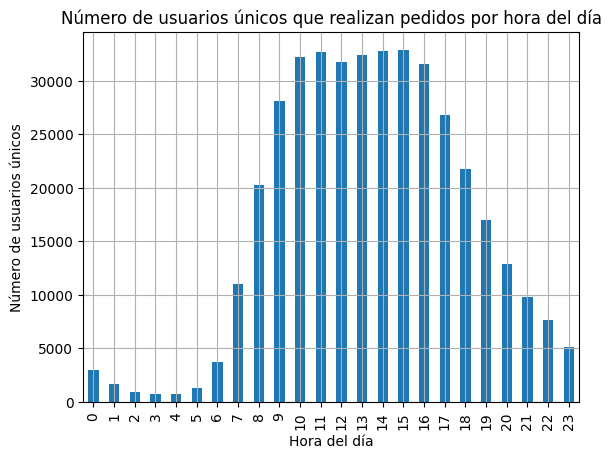

In [130]:
# Agrupar y contar pedidos por hora
pedidos_por_hora = df_orders.groupby('order_hour_of_day')['user_id'].nunique()

# Crear el gráfico de barras usando .plot()
pedidos_por_hora.plot(kind='bar', 
                      title='Número de usuarios únicos que realizan pedidos por hora del día',
                      xlabel='Hora del día',
                      ylabel='Número de usuarios únicos',
                      grid=True)
plt.show()

Escribe aquí tus conclusiones

Se encuentra que la hora pico de realización de pedidos está entre las 10:00 y las 16:00 que es donde se realizan mas de 30000 pedidos.

### [A3] ¿Qué día de la semana compran víveres las personas?

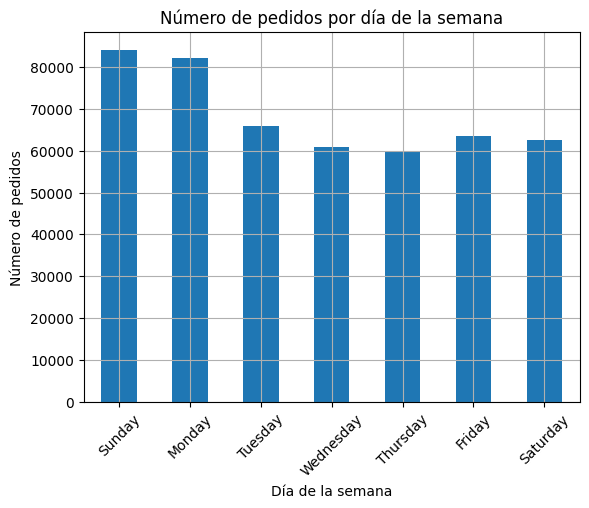

In [131]:
# Agrupar y contar pedidos por día
days_week = ['Sunday', 'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday']
pedidos_por_dia = df_orders.groupby('order_dow')['user_id'].count()
pedidos_por_dia.index = days_week

# Crear el gráfico de barras usando .plot()
pedidos_por_dia.plot(kind = 'bar', 
                     title = 'Número de pedidos por día de la semana',
                     xlabel = 'Día de la semana',
                     ylabel = 'Número de pedidos',
                     rot = 45,
                     grid = True)

plt.show()

Escribe aquí tus conclusiones

Los días domingo y lunes son los días de mayor volumen de ventas en comparación con el resto de semana. se tiene en promedio entre 15000 y 20000 ordenes mas.

### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

días minimos de espera entre pedidos: 0.0
días máximos de espera entre pedidos: 30.0


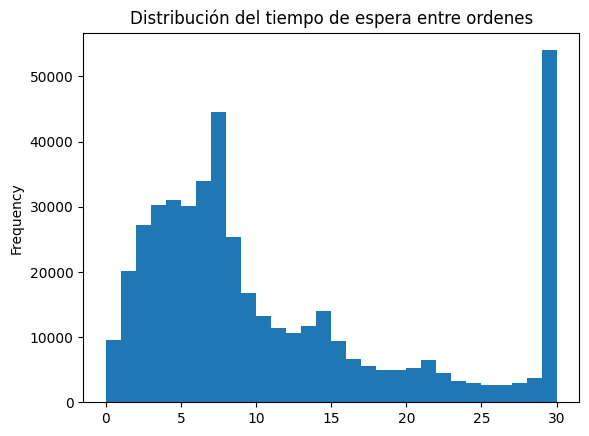

In [132]:
#Eliminar valores ausentes:
days_off = df_orders['days_since_prior_order'].dropna()
print(f"días minimos de espera entre pedidos: {days_off.min()}")
print(f"días máximos de espera entre pedidos: {days_off.max()}")

#Gráfico:
days_off.plot(kind = 'hist',
             bins = 30,
             title = 'Distribución del tiempo de espera entre ordenes',
             xlabel = 'Días desde el pedido anterior',
             ylabel = 'Número de ordenes')
plt.show()             


Escribe aquí tus conclusiones

Se observan claramente 3 datos clave tendencias:
1. Hay una gran parte de los pedidos que se piden de manera semanal, lo que es coherente con la tasa de pedidos esperada en un mercado.
2. Gran parte del espectro de ordenes se realizan dentro de la semana, entre 3 y 10 días entre pedidos. Esta es una tendencia esperada para ventas de abarrotes.
3. Otra gran parte de los pedidos, y es en mayoria, se piden una vez al mes. Habría que revisar que tipo de elementos se vende de manera mensual para determinar el tipo de tendencia de rotación de productos.

# [B] Intermedio (deben completarse todos para aprobar)

1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.

In [133]:
#Agrupar datos del miércoles:
order_wed = df_orders[df_orders['order_dow'] == 3]

In [134]:
#Agrupar datos del sábado:
order_sat = df_orders[df_orders['order_dow'] == 6]

In [135]:
#Filtrar pedidos por hora para ambos días:
order_wed_cont = order_wed.groupby('order_hour_of_day')['user_id'].count()
order_sat_cont = order_sat.groupby('order_hour_of_day')['user_id'].count()

#Totalizar número de pedidos:
print(f"El número total de ordenes el miércoles es: {order_wed['user_id'].count()}")
print(f"El número total de ordenes el sábado es: {order_sat['user_id'].count()}")

El número total de ordenes el miércoles es: 60897
El número total de ordenes el sábado es: 62649


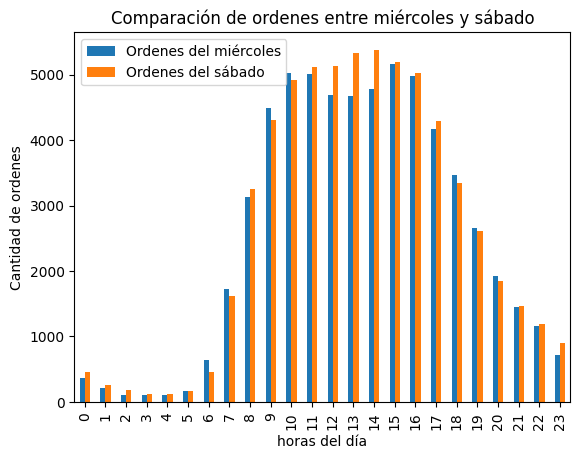

In [136]:
#Gráfico de barras
#Dataframe con los dos días:
comp = pd.DataFrame({'Ordenes del miércoles':order_wed_cont, 'Ordenes del sábado':order_sat_cont})

comp.plot(kind='bar', xlabel = 'horas del día', ylabel = 'Cantidad de ordenes', title = 'Comparación de ordenes entre miércoles y sábado')
plt.show()

Escribe aquí tus conclusiones

La distribución de pedidos en los días miércoles y sábados se comporta de manera similar en cuanto a número de ordenes realizadas con valores cercanos a 60000. 
sin embargo, se observa que en el rango de horario de 11:00 a 13:00 los pedidos decaen los días miércoles. Esto puede deberse a factores laborales, donde el usuario tiene poco tiempo para revisar sus compras en línea.
En comparación son este mismo rango horario donde se encuentran la mayor cantidad de ordenes el día sábado.

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

In [137]:
#Separar ordenes por usuario
order_user = df_orders.groupby('user_id')['order_number'].count()
#Distribución de pedidos por usuario
dist_order = order_user.value_counts()
print(dist_order)
print(dist_order.sum())

1     55357
2     36508
3     21547
4     13498
5      8777
6      6012
7      4240
8      3019
9      2152
10     1645
11     1308
12      947
13      703
14      512
15      437
16      263
17      184
18      121
19       85
20       52
22       23
21       22
23       19
24        3
25        1
26        1
28        1
Name: order_number, dtype: int64
157437


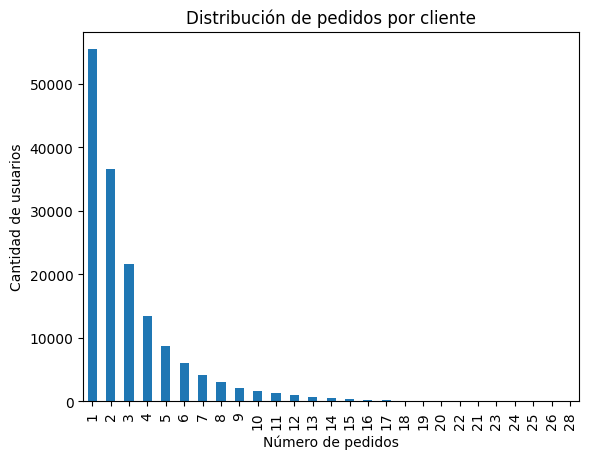

In [138]:
#Gráfica de distribución
dist_order.plot(kind = 'bar', xlabel = 'Número de pedidos', ylabel = 'Cantidad de usuarios', title = 'Distribución de pedidos por cliente')
plt.show()

Escribe aquí tus conclusiones

De acuerdo con la distribución de pedidos obtenida, se observa un comportamiento descendente, lo cual puede ser normal para una tienda de abarrotes en linea que se encuentra en una etapa de crecimiento. Si la tienda ya tiene un buen tiempo establecido, este comportamiento puede ser señal de que se tienen muchas oportunidades de mejora en cuanto a fidelización de los clientes.
Se encuentra también que cerca del 35% de los clientes realiza un único pedido.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [139]:
#Agrupar los productos en df_ordprod por 'product_id'
prod_top = df_ordprod.groupby('product_id')['order_id'].count()

In [140]:
#Ordenar el listado por orden descendente
orderedprod = prod_top.sort_values(ascending = False).reset_index()
print(orderedprod.head(20))

    product_id  order_id
0        24852     66050
1        13176     53297
2        21137     37039
3        21903     33971
4        47209     29773
5        47766     24689
6        47626     21495
7        16797     20018
8        26209     19690
9        27845     19600
10       27966     19197
11       22935     15898
12       24964     15292
13       45007     14584
14       39275     13879
15       49683     13675
16       28204     12544
17        5876     12232
18        8277     11993
19       40706     11781


In [141]:
#Combinación de los productos top con el dataframe df_products:
df_tot = orderedprod.merge(df_products, on = 'product_id')
df_tot = df_tot.rename(columns = {'order_id': 'times_ordered'})
print(df_tot.head(20))

    product_id  times_ordered              product_name  aisle_id  \
0        24852          66050                    BANANA        24   
1        13176          53297    BAG OF ORGANIC BANANAS        24   
2        21137          37039      ORGANIC STRAWBERRIES        24   
3        21903          33971      ORGANIC BABY SPINACH       123   
4        47209          29773      ORGANIC HASS AVOCADO        24   
5        47766          24689           ORGANIC AVOCADO        24   
6        47626          21495               LARGE LEMON        24   
7        16797          20018              STRAWBERRIES        24   
8        26209          19690                     LIMES        24   
9        27845          19600        ORGANIC WHOLE MILK        84   
10       27966          19197       ORGANIC RASPBERRIES       123   
11       22935          15898      ORGANIC YELLOW ONION        83   
12       24964          15292            ORGANIC GARLIC        83   
13       45007          14584     

Escribe aquí tus conclusiones

Al realizar el filtrado de los 20 productos mas solicitados se encuentra lo siguiente:
1. Las bananas son el producto mas pedido en la tienda con 66050 veces pedido.
2. En general las frutas y verduras son los elementos mas comprados en la tienda. Esto es normal para una tienda de abarrotes.
3. Se observa un interés marcado por los productos orgánicos, lo cual es algo muy usual para la gente que realiza compras en tiendas en línea.
4. El único producto que no es ni fruta ni verdura comprado en el top de productos es leche, lo cual también es una tendencia en las compras de abarrotes.

# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [142]:
#Agrupación de productos comprados en cada pedido:
prod_number = df_ordprod.groupby('order_id').size()
print(prod_number)

order_id
4          13
9          15
11          5
19          3
20          8
           ..
3421034    17
3421053     9
3421071     5
3421077     4
3421079     1
Length: 450046, dtype: int64


In [143]:
#Análisis estadístico de las ordenes:
print(prod_number.describe())

count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
dtype: float64


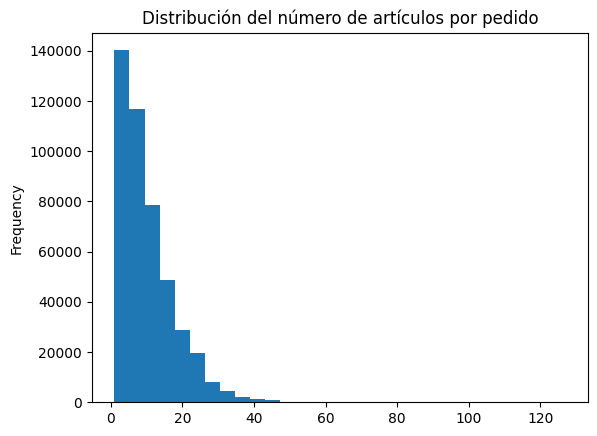

In [144]:
# Histograma para mostrar la distribución
prod_number.plot(kind = 'hist', bins = 30, title = 'Distribución del número de artículos por pedido', xlabel = 'Número de artículos por pedido', ylabel = 'Frecuencia')
plt.show()

Escribe aquí tus conclusiones

Una vez establecida la distribución de pedidos, y con el análisis estadístico de los mismos se puede encontrar que:
1. La gran mayoria de pedidos son solo por 1 a 4 artículos, y la distribución de número de artículos por pedidos tiende a disminuir con el aumento de artículos. Esto es un comportamiento que normal para las compras en un ecomerce.
2. El promedio de artículos comprados por pedido es cercano a 10 artículos, aunque el 50% de los pedidos son por 8 artículos. Al observar la distribución gráfica se encuentran pedidos que se realizan por mas de 40 artículos, lo que puede ocasionar que la media y la mediana no sean iguales.
3. Las compras realizadas por lo general son compras por pequeñas cantidades, no mayores a 20 artículos y se tienen muy pocas ventas de mas de 40 artículos.

### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [145]:
#Segregar los artículos que se piden nuevamente:
reord_prod = df_ordprod[df_ordprod['reordered'] == 1]

In [146]:
#Agrupar los artículos por 'product_id'
reord_prod_top = reord_prod.groupby('product_id')['order_id'].count()

In [147]:
#Agruparlos de manera descendente, iniciando una nueva indexación:
reordprod = reord_prod_top.sort_values(ascending = False).reset_index()

In [148]:
#Combinación de productos con df_products de acuerdo a 'product_id' para determinar los nombres:
df_reord = reordprod.merge(df_products, on = 'product_id')
df_reord = df_reord.rename(columns = {'order_id': 'times reordered'})
print(df_reord.head(20))

    product_id  times reordered              product_name  aisle_id  \
0        24852            55763                    BANANA        24   
1        13176            44450    BAG OF ORGANIC BANANAS        24   
2        21137            28639      ORGANIC STRAWBERRIES        24   
3        21903            26233      ORGANIC BABY SPINACH       123   
4        47209            23629      ORGANIC HASS AVOCADO        24   
5        47766            18743           ORGANIC AVOCADO        24   
6        27845            16251        ORGANIC WHOLE MILK        84   
7        47626            15044               LARGE LEMON        24   
8        27966            14748       ORGANIC RASPBERRIES       123   
9        16797            13945              STRAWBERRIES        24   
10       26209            13327                     LIMES        24   
11       22935            11145      ORGANIC YELLOW ONION        83   
12       24964            10411            ORGANIC GARLIC        83   
13    

Escribe aquí tus conclusiones

Luego de realizar técnicas de filtrado y agrupación se encuentran que:
1. los 20 productos que mas se ordenan nuevamente corresponden a frutas y verduras.
2. El producto mas reordenado es el banano, solicitado por 55763 veces.
3. Se encuentra una tendencia a pedir frutas y verduras de caracter orgánico, lo que corresponde a las nuevas tendencias de consumo.

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [149]:
#Unión de los 2 dataframes:
df_propor = pd.DataFrame({'total order': prod_top, 'total reorder': reord_prod_top}).fillna(0)

# Calcular la proporción de reorden (mantener entre 0-1, no multiplicar por 100)
df_propor['order_rate'] = (df_propor['total reorder'] / df_propor['total order'])

# Resetear índice para tener product_id como columna
df_propor = df_propor.reset_index()

# Hacer merge con df_products para obtener los nombres
df_propor_complete = df_propor.merge(df_products, on='product_id')

# Mostrar la tabla solicitada con product_id, product_name y tasa de recompra
print(df_propor_complete[['product_id', 'product_name', 'order_rate']].head(20))



    product_id                                       product_name  order_rate
0            1                         CHOCOLATE SANDWICH COOKIES    0.564286
1            2                                   ALL-SEASONS SALT    0.000000
2            3               ROBUST GOLDEN UNSWEETENED OOLONG TEA    0.738095
3            4  SMART ONES CLASSIC FAVORITES MINI RIGATONI WIT...    0.510204
4            7                     PURE COCONUT WATER WITH ORANGE    0.500000
5            8                  CUT RUSSET POTATOES STEAM N' MASH    0.315789
6            9                  LIGHT STRAWBERRY BLUEBERRY YOGURT    0.761905
7           10     SPARKLING ORANGE JUICE & PRICKLY PEAR BEVERAGE    0.448071
8           11                                  PEACH MANGO JUICE    0.625000
9           12                         CHOCOLATE FUDGE LAYER CAKE    0.390244
10          13                                  SALINE NASAL MIST    0.500000
11          14                     FRESH SCENT DISHWASHER CLEANE

In [150]:
#Análisis estadístico de df_propor:
print(df_propor_complete['order_rate'].describe())
print()

#Análisis estadístico sin tener en cuenta los valores de 0 y 100%:
propor_filtered = df_propor[(df_propor['order_rate'] > 0) & (df_propor['order_rate'] < 100)]
print(propor_filtered['order_rate'].describe())

count    45573.000000
mean         0.386707
std          0.272132
min          0.000000
25%          0.166667
50%          0.408163
75%          0.575758
max          1.000000
Name: order_rate, dtype: float64

count    36228.000000
mean         0.486458
std          0.211266
min          0.010989
25%          0.333333
50%          0.500000
75%          0.616071
max          1.000000
Name: order_rate, dtype: float64


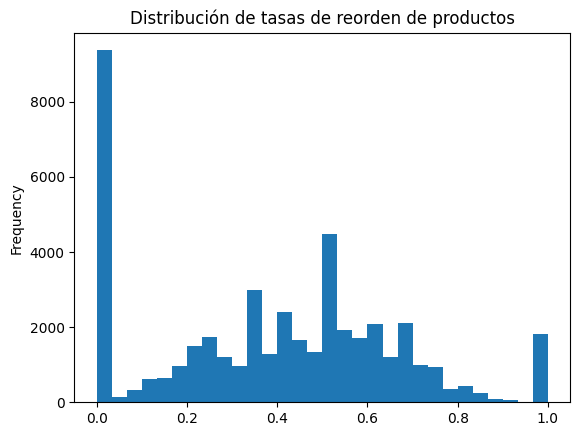

In [151]:
#Generación de gráfico histograma:
df_propor['order_rate'].plot(kind = 'hist', bins = 30, title = 'Distribución de tasas de reorden de productos', xlabel = 'Tasa de reorden (%)', ylabel = 'Número de productos')
plt.show()

Escribe aquí tus conclusiones

Luego del desarrollo del código se encuentra que:
1. Cerca de 10000 ocasiones, mas del 20% de los artículos se compran por única vez. Esto puede ser por falta de fidelización, o por ser compras especiales.
2. En aproximadamente 2000 artículos, las compras corresponden a ordenes que ya se habían realizado previamente.
3. La fidelización de cerca de 5000 artículos es del 50%.

### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [152]:
#Unión de las tablas df_orders y df_ordprod:
df_users = df_orders.merge(df_ordprod, on = 'order_id')

#Agrupar por usuario:
users_tot = df_users.groupby('user_id')['reordered'].count()
print(users_tot.head())

user_id
2    26
4     2
5    12
6     4
7    14
Name: reordered, dtype: int64


    user_id  reorder_rate
0         2      0.038462
1         4      0.000000
2         5      0.666667
3         6      0.000000
4         7      0.928571
5        11      0.200000
6        12      0.250000
7        13      0.565217
8        14      0.360656
9        15      0.538462
10       16      0.531250
11       17      0.716981
12       19      0.291667
13       20      0.000000
14       21      0.400000
15       22      1.000000
16       24      0.500000
17       26      0.437500
18       27      0.658824
19       28      0.500000
count    149626.000000
mean          0.494853
std           0.292685
min           0.000000
25%           0.272727
50%           0.500000
75%           0.724138
max           1.000000
Name: reorder_rate, dtype: float64


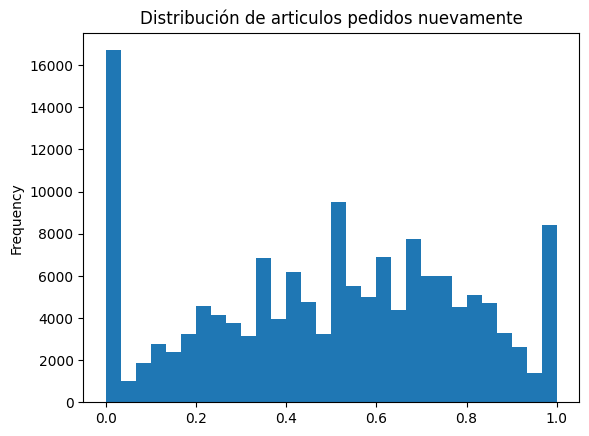

In [160]:
# Calcular productos reordenados por usuario
users_reord = df_users.groupby('user_id')['reordered'].sum()

# Calcular la proporción de reorden por usuario
user_reorder_rate = (users_reord / users_tot).reset_index()
user_reorder_rate.columns = ['user_id', 'reorder_rate']

print(user_reorder_rate.head(20))  

#Análisis estadístico
print(user_reorder_rate['reorder_rate'].describe())

#Histograma
user_reorder_rate['reorder_rate'].plot(kind = 'hist', bins = 30, title = 'Distribución de articulos pedidos nuevamente')
plt.show()

Escribe aquí tus conclusiones

El análisis estadístico y el histograma muestran lo siguiente:
1. Cerca del 50% de los articulos solicitados por el cliente ya los había pedido pregviamente.
2. El histograma muestra una tendencia a que los usuarios vuelven a pedir los articulos que ya habían comprado anteriormente.
3. Se observa que en mas de 16000 ocasiones, los articulos son comprados por única vez, pero a su vez, se tiene un buen número de pedidos que siempre se vuelven a solicitar.
4. Se observa que en general, el usuario se fideliza con la recompra de articulos ya que tiende a solicitarlos nuevamente

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [61]:
#Filtrar por articulos puestos en el carro inicialmente:
prod_ini = df_ordprod[df_ordprod['add_to_cart_order']==1]

In [62]:
#Agrupar por producto:
agg_prod_ini = prod_ini.groupby('product_id')['order_id'].count()

#Ordenar los resultados de mayor a menor, reiniciando indices
prod_ini_ord = agg_prod_ini.sort_values(ascending = False).reset_index()
print(prod_ini_ord.head(20))

    product_id  order_id
0        24852     15562
1        13176     11026
2        27845      4363
3        21137      3946
4        47209      3390
5        21903      3336
6        47766      3044
7        19660      2336
8        16797      2308
9        27966      2024
10       44632      1914
11       49235      1797
12       47626      1737
13         196      1733
14       38689      1397
15       26209      1370
16       12341      1340
17        5785      1310
18       27086      1309
19       43352      1246


In [63]:
#Identificar los productos a partir de df_products
df_prod_ord = prod_ini_ord.merge(df_products, on = 'product_id')
df_prod_ord = df_prod_ord.rename(columns = {'order_id':'Frequency'})
print(df_prod_ord.head(20))

    product_id  Frequency                 product_name  aisle_id  \
0        24852      15562                       BANANA        24   
1        13176      11026       BAG OF ORGANIC BANANAS        24   
2        27845       4363           ORGANIC WHOLE MILK        84   
3        21137       3946         ORGANIC STRAWBERRIES        24   
4        47209       3390         ORGANIC HASS AVOCADO        24   
5        21903       3336         ORGANIC BABY SPINACH       123   
6        47766       3044              ORGANIC AVOCADO        24   
7        19660       2336                 SPRING WATER       115   
8        16797       2308                 STRAWBERRIES        24   
9        27966       2024          ORGANIC RASPBERRIES       123   
10       44632       1914   SPARKLING WATER GRAPEFRUIT       115   
11       49235       1797          ORGANIC HALF & HALF        53   
12       47626       1737                  LARGE LEMON        24   
13         196       1733                       

Escribe aquí tus conclusiones

Una vez se realizan las tareas de filtrado y agrupación se encuentra lo siguiente:
1. las bananas siguen siendo el producto que mas se adiciona de primero al carrito con 15562 ocasiones.
2. Son las frutas y verduras, especialmente las de tipo orgánico los productos más adicionados inicialmente al carro de compras.
3. En esta ocasión, también se adicionan bebidas como agua, soda y leche.

### Conclusion general del proyecto:




Se ha realizado un análisis completo de la plataforma Instacart trabajando con 5 tablas, las cuales fueron acondicionadas, filtradas y limpiadas para poder realizar un análisis detallado de las tendencias de compra de los usuarios.

### Principales hallazgos:

1. **Tendencias de compra**: Se concentran en frutas y verduras, especialmente productos orgánicos

2. **Preferencias del usuario**: Los alimentos orgánicos marcan la tendencia de preferencia de compra

3. **Productos complementarios**: Bebidas como agua, soda y leche también son artículos de compra constante

4. **Perfil del usuario**: Se concentra en comprar productos frescos, con altos estándares de calidad y frescura

5. **Comportamiento de compra**: Los usuarios compran entre 8 y 10 productos por compra en promedio

### Conclusión:
El análisis revela un perfil de usuario consciente de la calidad, que prioriza productos frescos y orgánicos, con patrones de compra regulares y una buena tasa de fidelización del 50%.
